In [22]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")


In [2]:
#loading the dataset from the  provided url
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

df = pd.read_csv(url)
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
#inpecting the data
print("Dataframe shape:", df.shape)
print("Dataframe info:")
df.info()
print("Dataframe description:")
print(df.describe().T.round(2))
print("Dataframe columns:")
print(df.columns)
print("Dataframe missing values:")
print(df.isnull().sum())
print("Dataframe duplicates:")
print(df.duplicated().sum())
print("Dataframe  categoorical unique values:")
print(df["ocean_proximity"].value_counts())
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage)

Dataframe shape: (20640, 10)
Dataframe info:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB
Dataframe description:
                      count       mean        std       min        25%  \
longitude           20640.0    -119.57       2.00   -124.35    -121.80   
latitude            20640.0      35.63       2.14 

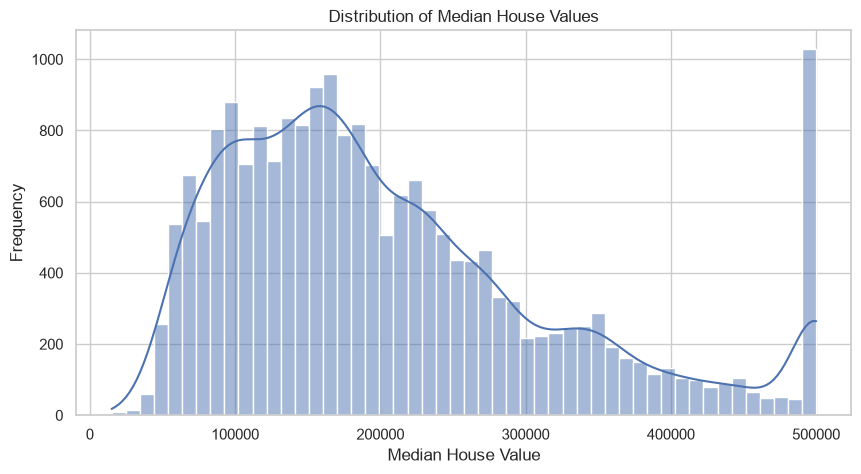

In [4]:
#examining the target variable
plt.figure(figsize=(10, 5))
sns.histplot(df['median_house_value'], bins=50, kde=True)
plt.title('Distribution of Median House Values')
plt.xlabel('Median House Value')
plt.ylabel('Frequency')
plt.show()

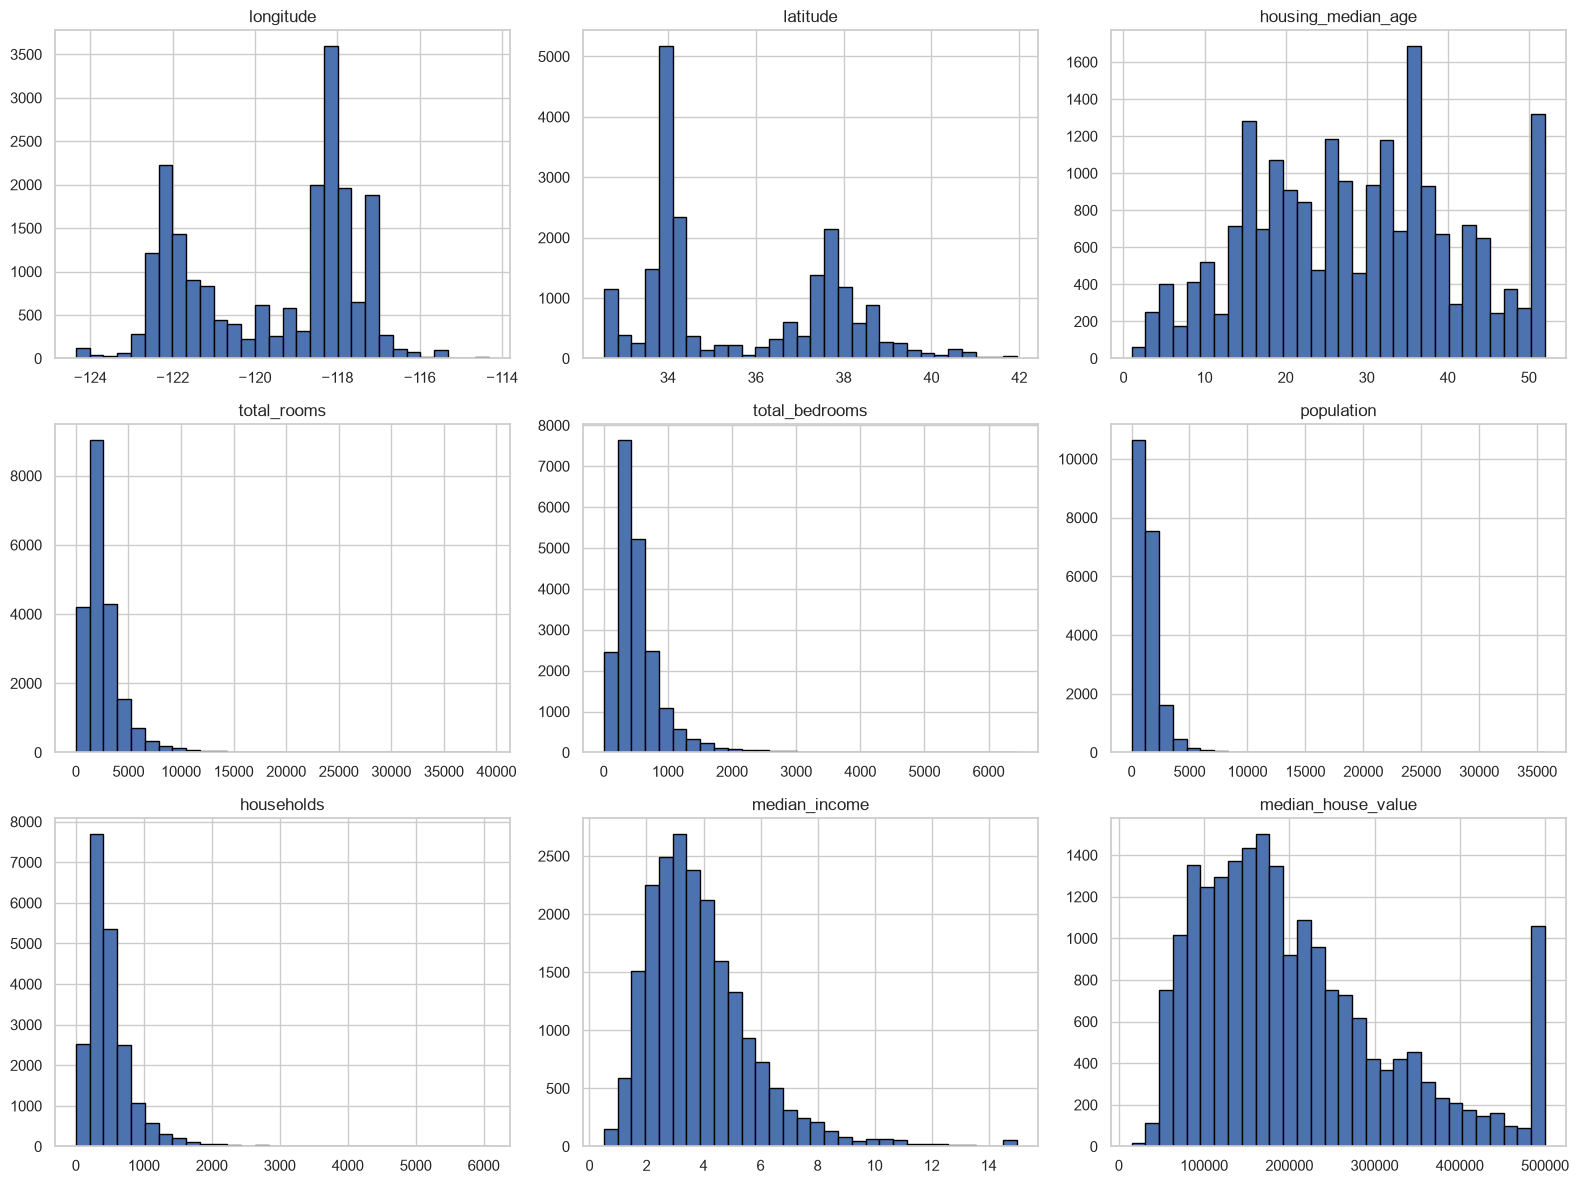

In [5]:
#numerical features distribution
df.hist(figsize=(16, 12), bins=30, edgecolor='black')
plt.tight_layout()
plt.show()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


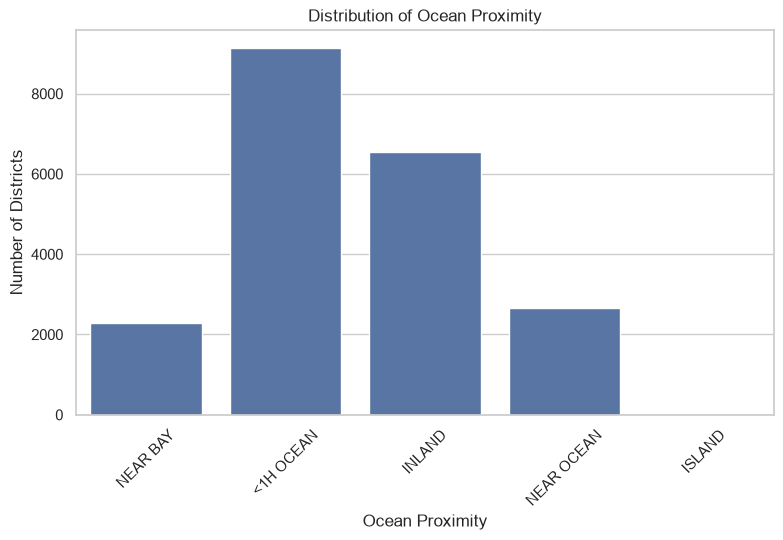

In [6]:
#examining categorical features
print(df['ocean_proximity'].value_counts())

plt.figure(figsize=(9, 5))
sns.countplot(data=df, x='ocean_proximity')
plt.title('Distribution of Ocean Proximity')
plt.xlabel('Ocean Proximity')
plt.ylabel('Number of Districts')
plt.xticks(rotation=45)
plt.show()

In [7]:
#handling missing values
# Count missing values
missing_values = df.isnull().sum()

# Calculate missing percentages
missing_percent = (df.isnull().sum() / len(df)) * 100

# Combine results
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percent
})

missing_summary

,Missing Values,Missing Percentage
longitude,0,0.000000
latitude,0,0.000000
housing_median_age,0,0.000000
total_rooms,0,0.000000
total_bedrooms,207,1.002907
population,0,0.000000
households,0,0.000000
median_income,0,0.000000
median_house_value,0,0.000000
ocean_proximity,0,0.000000


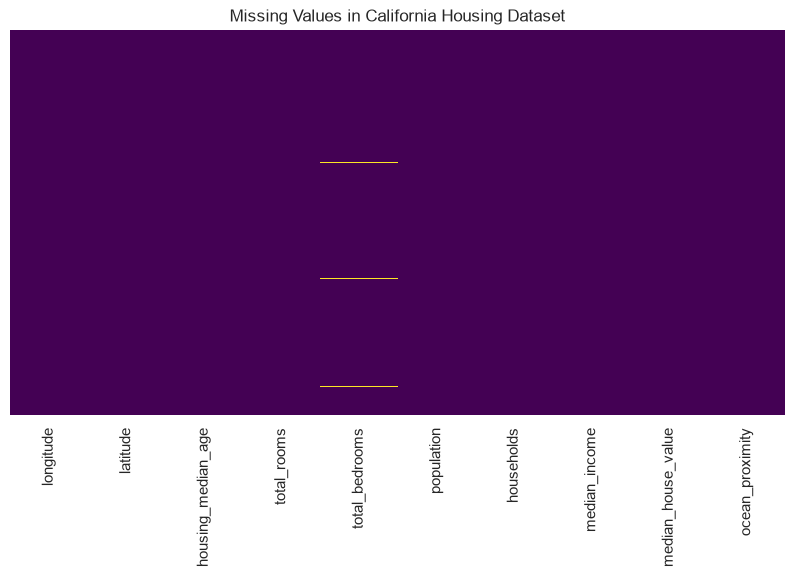

In [8]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), 
            cbar=False, 
            yticklabels=False, 
            cmap='viridis')
plt.title('Missing Values in California Housing Dataset')
plt.show()

In [9]:
#relationships
# Select numerical columns
numerical_df = df.select_dtypes(include=['int64', 'float64'])
# Calculate correlation matrix
correlation_matrix = numerical_df.corr()

# Display correlation matrix
correlation_matrix

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000


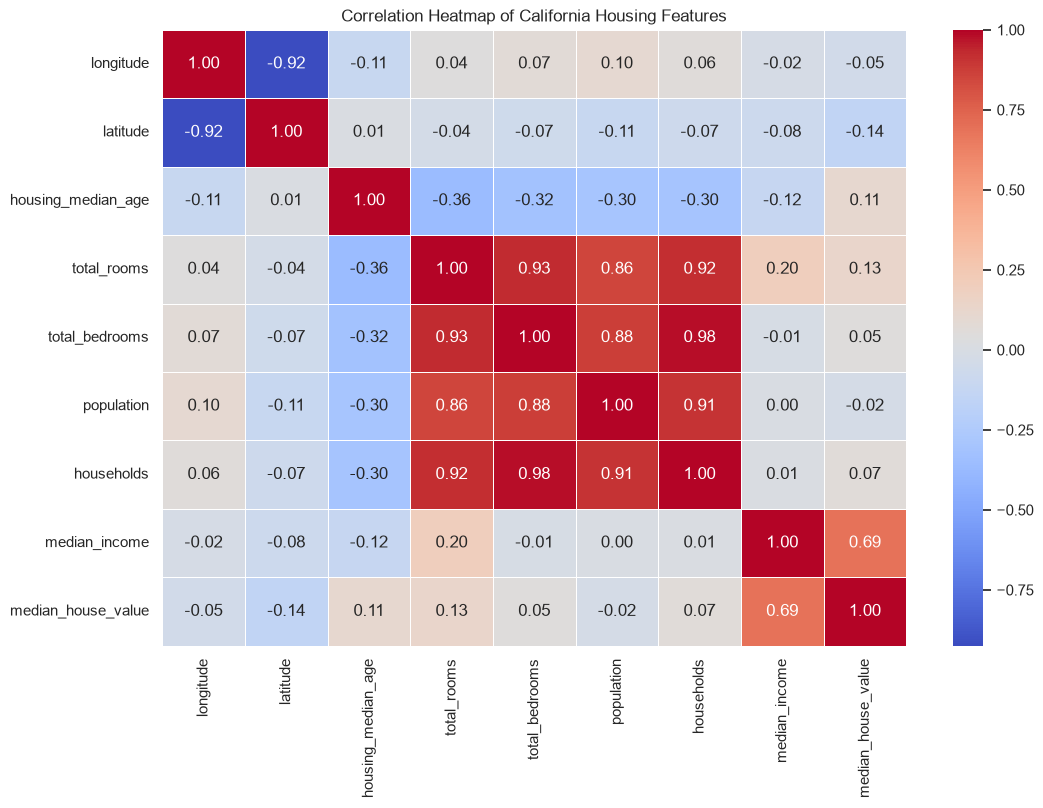

In [10]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Correlation Heatmap of California Housing Features')
plt.show()

In [11]:
# Sort correlations with target variable
target_correlation = correlation_matrix['median_house_value'].sort_values(
    ascending=False
)
target_correlation

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

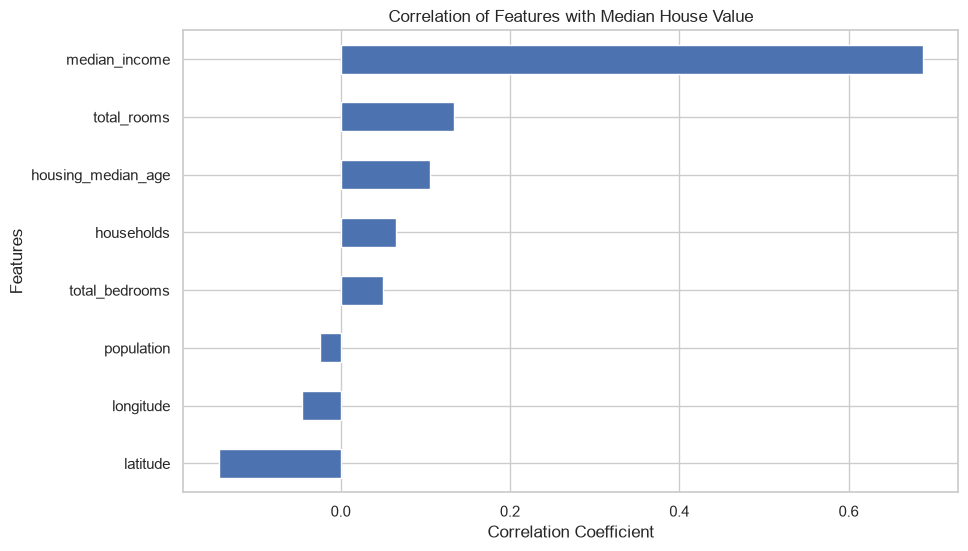

In [12]:
plt.figure(figsize=(10, 6))
target_correlation.drop('median_house_value').sort_values().plot(
    kind='barh'
)
plt.title('Correlation of Features with Median House Value')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Features')
plt.show()

In [13]:
# Remove target variable
feature_corr = numerical_df.drop(
    columns=['median_house_value']
).corr()

# Extract upper triangle to avoid duplicate pairs
upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

# Identify highly correlated pairs
high_corr = (
    upper_triangle.stack()
    .reset_index()
)

high_corr.columns = ['Feature 1', 'Feature 2', 'Correlation']

# Display pairs with absolute correlation above 0.7
high_corr = high_corr[
    high_corr['Correlation'].abs() > 0.7
].sort_values(
    by='Correlation',
    key=abs,
    ascending=False
)

high_corr

,Feature 1,Feature 2,Correlation
38,total_bedrooms,households,0.979728
28,total_rooms,total_bedrooms,0.930380
1,longitude,latitude,-0.924664
30,total_rooms,households,0.918484
46,population,households,0.907222
37,total_bedrooms,population,0.877747
29,total_rooms,population,0.857126


In [14]:
df_model = df.copy()
# Create new features
df_model['rooms_per_household'] = (
    df_model['total_rooms'] / df_model['households']
)

df_model['bedrooms_per_room'] = (
    df_model['total_bedrooms'] / df_model['total_rooms']
)

df_model['population_per_household'] = (
    df_model['population'] / df_model['households']
)

In [15]:
# Display the new features
df_model[[
    'rooms_per_household',
    'bedrooms_per_room',
    'population_per_household'
]].head()

,rooms_per_household,bedrooms_per_room,population_per_household
0,6.984127,0.146591,2.555556
1,6.238137,0.155797,2.109842
2,8.288136,0.129516,2.802260
3,5.817352,0.184458,2.547945
4,6.281853,0.172096,2.181467


In [16]:
df_model[[
    'rooms_per_household',
    'bedrooms_per_room',
    'population_per_household'
]].describe()

,rooms_per_household,bedrooms_per_room,population_per_household
count,20640.000000,20433.000000,20640.000000
mean,5.429000,0.213039,3.070655
std,2.474173,0.057983,10.386050
min,0.846154,0.100000,0.692308
25%,4.440716,0.175427,2.429741
50%,5.229129,0.203162,2.818116
75%,6.052381,0.239821,3.282261
max,141.909091,1.000000,1243.333333


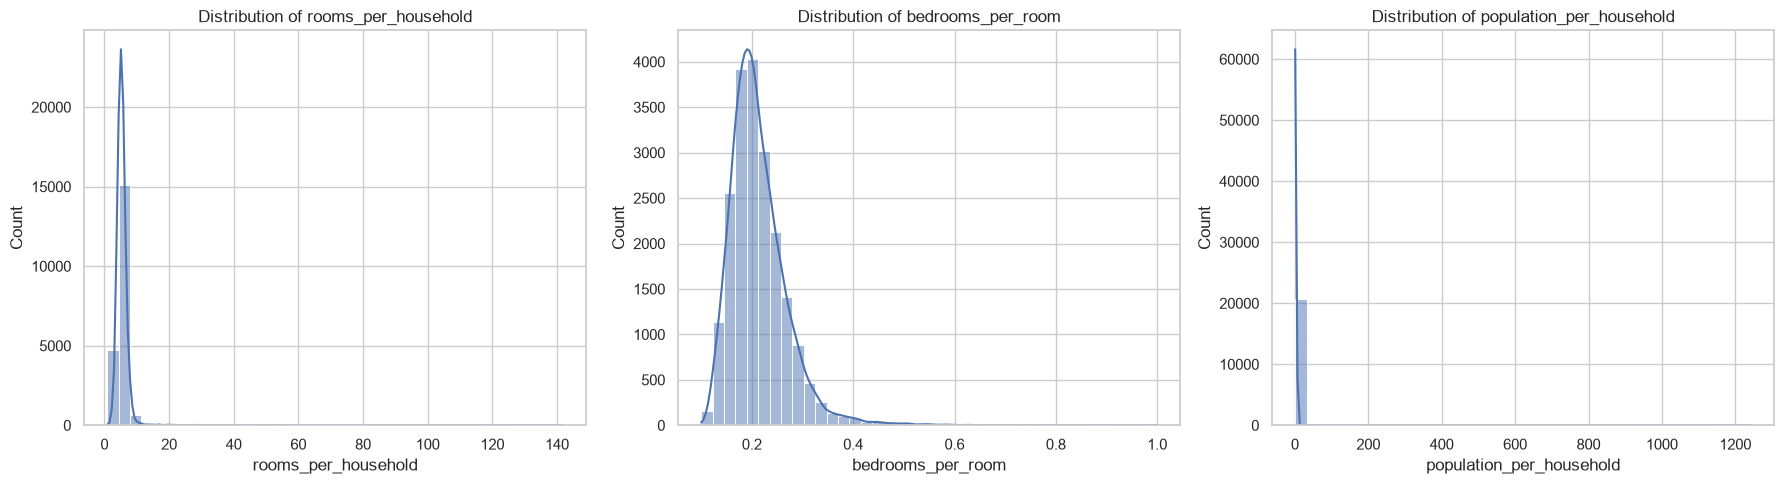

In [17]:
# Plot distributions of engineered features

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

features = [
    'rooms_per_household',
    'bedrooms_per_room',
    'population_per_household'
]

for ax, feature in zip(axes, features):
    sns.histplot(
        df_model[feature],
        bins=40,
        kde=True,
        ax=ax
    )
    ax.set_title(f'Distribution of {feature}')
    ax.set_xlabel(feature)

plt.tight_layout()
plt.show()

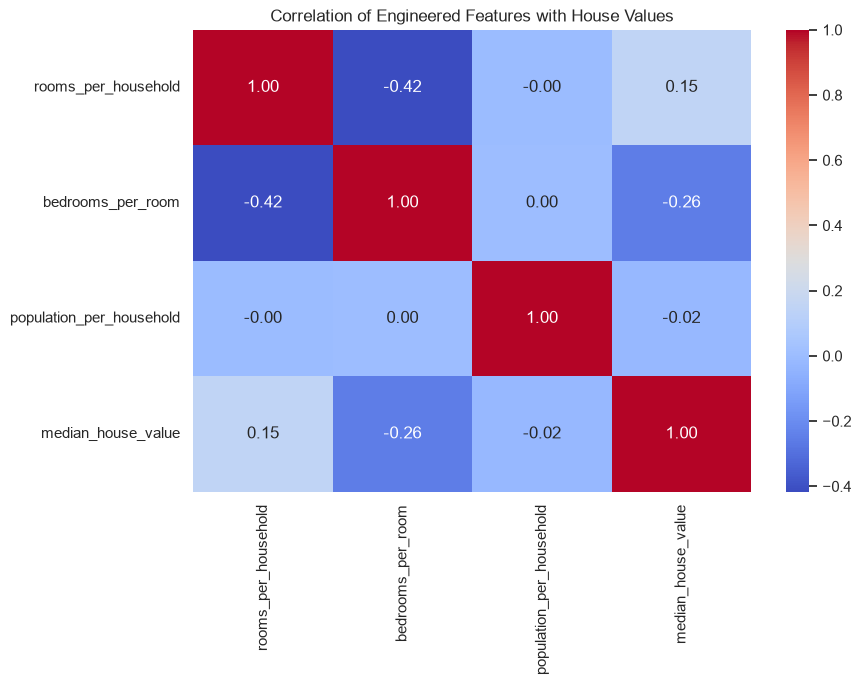

In [18]:
# Calculate correlations with target
engineered_corr = df_model[[
    'rooms_per_household',
    'bedrooms_per_room',
    'population_per_household',
    'median_house_value'
]].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    engineered_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation of Engineered Features with House Values')
plt.show()

In [19]:
print("Original dataset shape:", df.shape)
print("Updated dataset shape:", df_model.shape)

# Display all columns
df_model.columns.tolist()

Original dataset shape: (20640, 10)
Updated dataset shape: (20640, 13)


['longitude',
 'latitude',
 'housing_median_age',
 'total_rooms',
 'total_bedrooms',
 'population',
 'households',
 'median_income',
 'median_house_value',
 'ocean_proximity',
 'rooms_per_household',
 'bedrooms_per_room',
 'population_per_household']

In [20]:
# Separate independent and dependent variables
X = df_model.drop(columns=['median_house_value'])
y = df_model['median_house_value']
# Display dimensions
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 12)
Target shape: (20640,)


In [23]:
# Identify numerical features
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Identify categorical features
categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']

Categorical Features:
['ocean_proximity']


C:\Users\USER\AppData\Local\Temp\ipykernel_19400\4119418830.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [24]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
# Display dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (16512, 12)
Testing Features: (4128, 12)
Training Target: (16512,)
Testing Target: (4128,)


In [25]:
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("Total observations:", len(X_train) + len(X_test))

Training observations: 16512
Testing observations: 4128
Total observations: 20640


In [26]:
# Numerical preprocessing pipeline
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),

    ('interaction', PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    )),

    ('scaler', StandardScaler())
])

In [27]:
# Categorical preprocessing pipeline
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),

    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

In [28]:
# Combine numerical and categorical pipelines
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

In [29]:
# Create OLS pipeline
ols_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

In [30]:
# Fit model using training data
ols_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['longitude','latitude','housing_median_age',...,'rooms_per_household', 'bedrooms_per_room','population_per_household']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be auto

In [31]:
# Predict house values
y_pred_ols = ols_pipeline.predict(X_test)

In [32]:
# Compare actual and predicted values
comparison = pd.DataFrame({
    'Actual Values': y_test.values[:10],
    'Predicted Values': y_pred_ols[:10]
})
comparison

,Actual Values,Predicted Values
0,47700.0,-2.109052e+05
1,45800.0,4.600810e+05
2,500001.0,1.014618e+06
3,218600.0,6.526488e+05
4,278000.0,3.657467e+05
5,158700.0,1.084853e+06
6,198200.0,-2.801636e+04
7,157500.0,-1.369592e+05
8,340000.0,2.908325e+05
9,446600.0,4.887153e+05


In [33]:
# Calculate evaluation metrics
ols_mae = mean_absolute_error(y_test, y_pred_ols)

ols_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_ols)
)

ols_r2 = r2_score(y_test, y_pred_ols)

# Display results

print("OLS Regression Performance")
print("---------------------------")
print("MAE:", round(ols_mae, 2))
print("RMSE:", round(ols_rmse, 2))
print("R² Score:", round(ols_r2, 4))

OLS Regression Performance
---------------------------
MAE: 69788.74
RMSE: 179952.04
R² Score: -1.4712


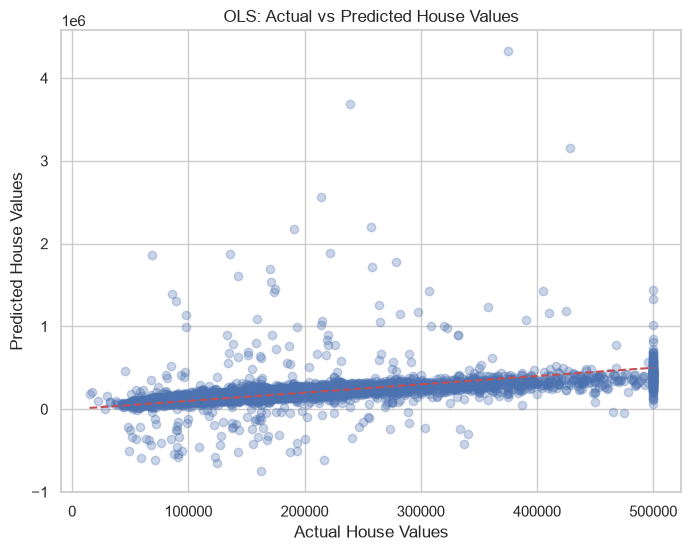

In [34]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_ols, alpha=0.3)
# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
plt.xlabel('Actual House Values')
plt.ylabel('Predicted House Values')
plt.title('OLS: Actual vs Predicted House Values')

plt.show()

In [35]:
# Calculate residuals
ols_residuals = y_test - y_pred_ols

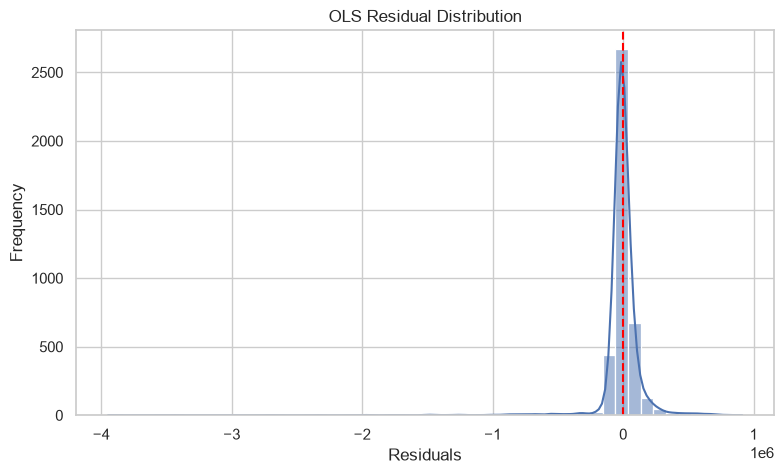

In [36]:
plt.figure(figsize=(9, 5))
sns.histplot(
    ols_residuals,
    bins=50,
    kde=True
)
plt.axvline(0, color='red', linestyle='--')
plt.title('OLS Residual Distribution')
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.show()

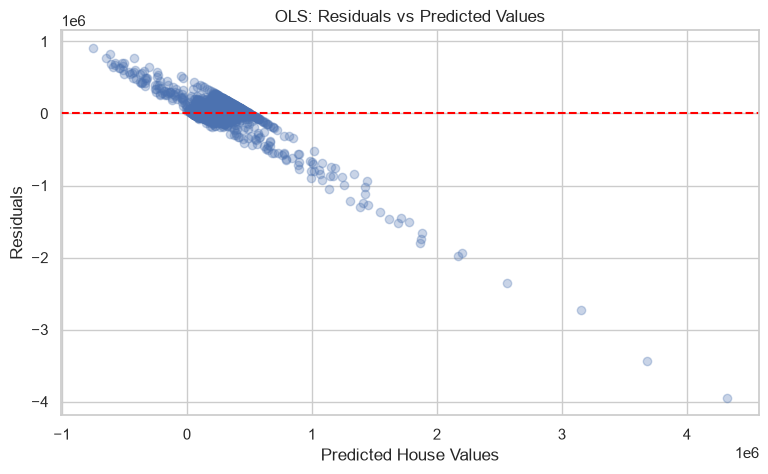

In [37]:
plt.figure(figsize=(9, 5))
plt.scatter(
    y_pred_ols,
    ols_residuals,
    alpha=0.3
)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted House Values')
plt.ylabel('Residuals')
plt.title('OLS: Residuals vs Predicted Values')
plt.show()

In [38]:
# Create Ridge pipeline
ridge_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

In [39]:
# Define alpha values
ridge_param_grid = {
    'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]
}

In [40]:
# Initialize GridSearchCV
ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

In [41]:
# Fit Ridge GridSearchCV
ridge_grid.fit(X_train, y_train)

Fitting 5 folds for each of 6 candidates, totalling 30 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...l', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to de

In [42]:
# Best alpha
print("Best Alpha:", ridge_grid.best_params_)
print("Best Cross-Validation RMSE:",
      -ridge_grid.best_score_)

Best Alpha: {'model__alpha': 1000}
Best Cross-Validation RMSE: 66932.61444800955


In [43]:
# Convert results into a DataFrame
ridge_results = pd.DataFrame(
    ridge_grid.cv_results_
)
ridge_results[[
    'param_model__alpha',
    'mean_test_score',
    'std_test_score'
]]

,param_model__alpha,mean_test_score,std_test_score
0,0.01,-103601.300551,64051.173783
1,0.10,-102603.125355,65862.828924
2,1.00,-99076.671066,61422.991954
3,10.00,-94833.818935,55191.576093
4,100.00,-73818.491201,17175.990337
5,1000.00,-66932.614448,1119.034800


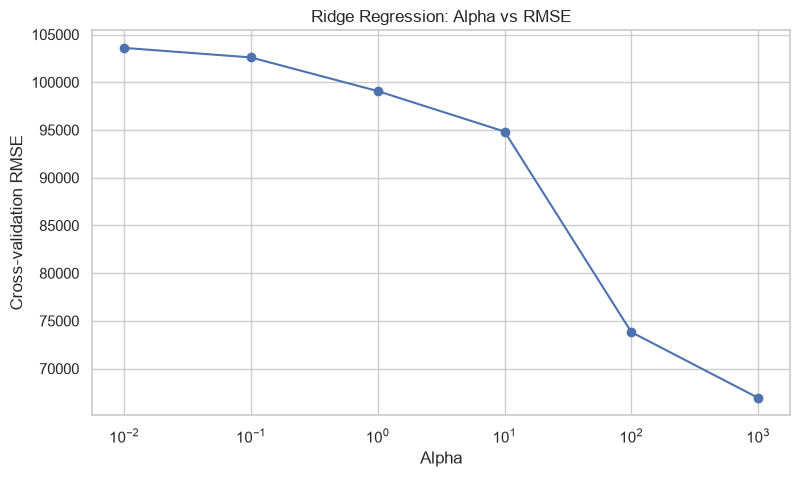

In [44]:
plt.figure(figsize=(9, 5))
plt.plot(
    ridge_results['param_model__alpha'],
    -ridge_results['mean_test_score'],
    marker='o'
)
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('Cross-validation RMSE')
plt.title('Ridge Regression: Alpha vs RMSE')
plt.show()

In [45]:
# Retrieve best Ridge model
best_ridge = ridge_grid.best_estimator_
# Make predictions
y_pred_ridge = best_ridge.predict(X_test)

In [46]:
# Calculate evaluation metrics
ridge_mae = mean_absolute_error(
    y_test, y_pred_ridge
)
ridge_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_ridge)
)
ridge_r2 = r2_score(
    y_test, y_pred_ridge
)
print("Ridge Regression Performance")
print("-----------------------------")
print("MAE:", round(ridge_mae, 2))
print("RMSE:", round(ridge_rmse, 2))
print("R² Score:", round(ridge_r2, 4))

Ridge Regression Performance
-----------------------------
MAE: 48412.6
RMSE: 67804.9
R² Score: 0.6492


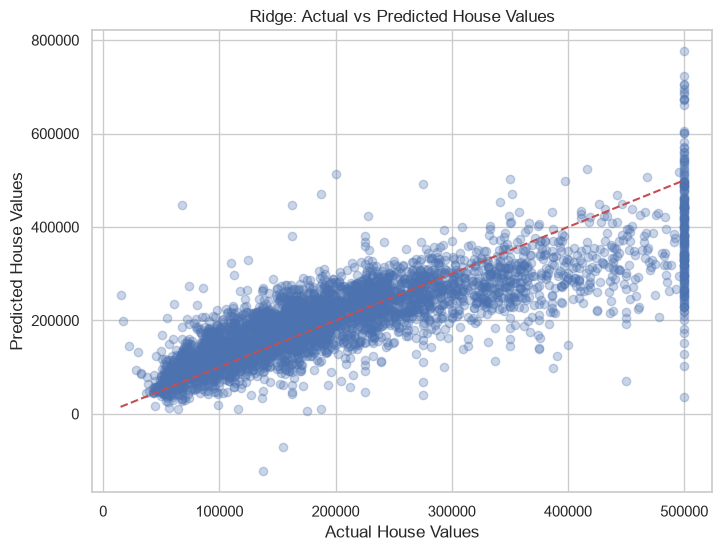

In [47]:
plt.figure(figsize=(8, 6))
plt.scatter(
    y_test,
    y_pred_ridge,
    alpha=0.3
)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
plt.xlabel('Actual House Values')
plt.ylabel('Predicted House Values')
plt.title('Ridge: Actual vs Predicted House Values')
plt.show()

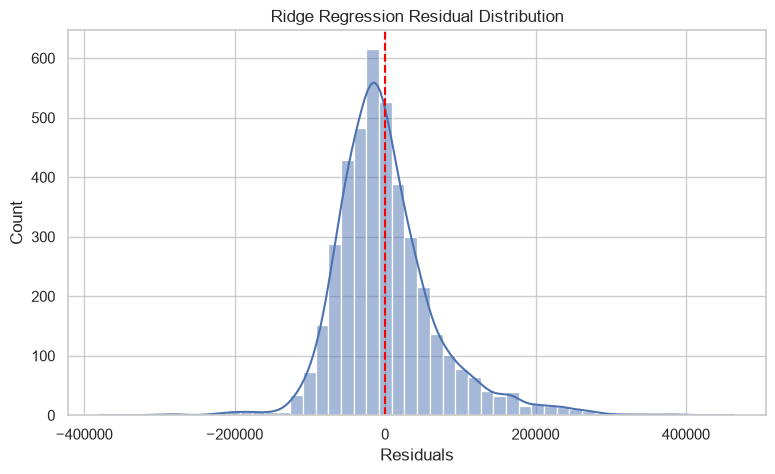

In [48]:
# Calculate residuals

ridge_residuals = y_test - y_pred_ridge

# Plot residual distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    ridge_residuals,
    bins=50,
    kde=True
)

plt.axvline(0, color='red', linestyle='--')

plt.title('Ridge Regression Residual Distribution')
plt.xlabel('Residuals')

plt.show()

In [49]:
# Create Lasso pipeline
lasso_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Lasso(max_iter=20000))
])

In [50]:
# Define alpha values
lasso_param_grid = {
    'model__alpha': [0.001, 0.01, 0.1, 1, 10, 100]
}

In [51]:
# Initialize GridSearchCV
lasso_grid = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

In [52]:
# Fit Lasso GridSearchCV
lasso_grid.fit(X_train, y_train)

Fitting 5 folds for each of 6 candidates, totalling 30 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...iter=20000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to de

In [53]:
# Display best hyperparameter
print("Best Alpha:", lasso_grid.best_params_)
print(
    "Best Cross-Validation RMSE:",
    -lasso_grid.best_score_
)

Best Alpha: {'model__alpha': 100}
Best Cross-Validation RMSE: 83340.56413643106


In [54]:
# Convert GridSearchCV results into DataFrame
lasso_results = pd.DataFrame(
    lasso_grid.cv_results_
)

lasso_results[[
    'param_model__alpha',
    'mean_test_score',
    'std_test_score'
]]

,param_model__alpha,mean_test_score,std_test_score
0,0.001,-97444.117163,57550.458975
1,0.010,-97458.694731,57580.621098
2,0.100,-97622.995839,57918.881111
3,1.000,-99428.141041,61618.801185
4,10.000,-102459.271158,68939.970846
5,100.000,-83340.564136,35385.087902


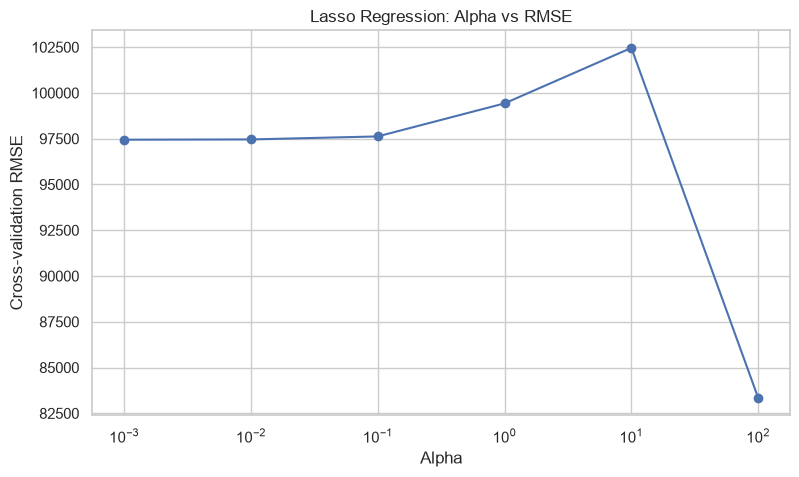

In [55]:
plt.figure(figsize=(9, 5))
plt.plot(
    lasso_results['param_model__alpha'],
    -lasso_results['mean_test_score'],
    marker='o'
)

plt.xscale('log')

plt.xlabel('Alpha')
plt.ylabel('Cross-validation RMSE')
plt.title('Lasso Regression: Alpha vs RMSE')

plt.show()

In [56]:
# Retrieve best Lasso model

best_lasso = lasso_grid.best_estimator_

# Predict house values

y_pred_lasso = best_lasso.predict(X_test)

In [57]:
# Calculate evaluation metrics

lasso_mae = mean_absolute_error(
    y_test, y_pred_lasso
)

lasso_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_lasso)
)

lasso_r2 = r2_score(
    y_test, y_pred_lasso
)

print("Lasso Regression Performance")
print("-----------------------------")

print("MAE:", round(lasso_mae, 2))
print("RMSE:", round(lasso_rmse, 2))
print("R² Score:", round(lasso_r2, 4))

Lasso Regression Performance
-----------------------------
MAE: 47484.97
RMSE: 66504.97
R² Score: 0.6625


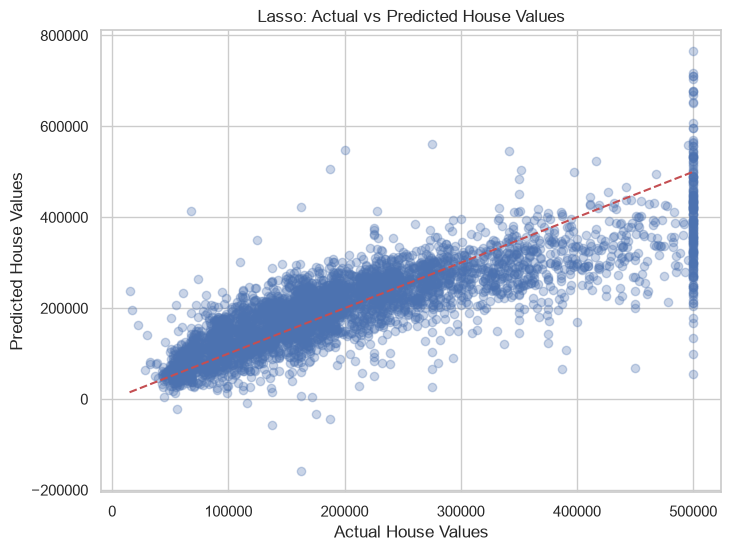

In [58]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_lasso,
    alpha=0.3
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Actual House Values')
plt.ylabel('Predicted House Values')

plt.title('Lasso: Actual vs Predicted House Values')

plt.show()

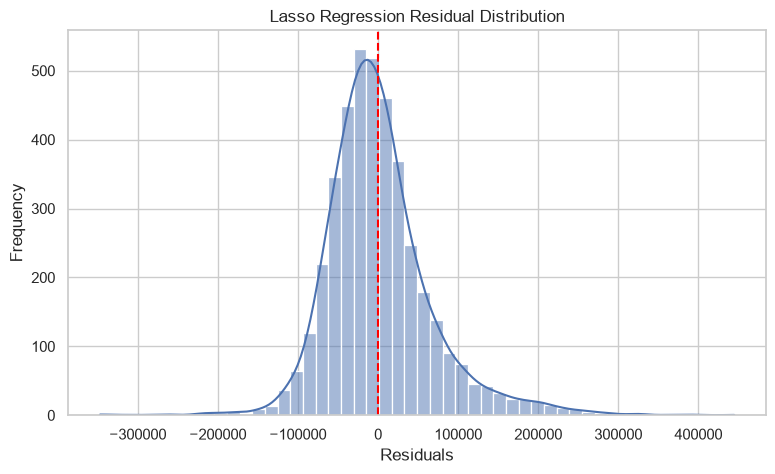

In [59]:
# Calculate residuals

lasso_residuals = y_test - y_pred_lasso

# Plot residual distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    lasso_residuals,
    bins=50,
    kde=True
)

plt.axvline(0, color='red', linestyle='--')

plt.title('Lasso Regression Residual Distribution')
plt.xlabel('Residuals')
plt.ylabel('Frequency')

plt.show()

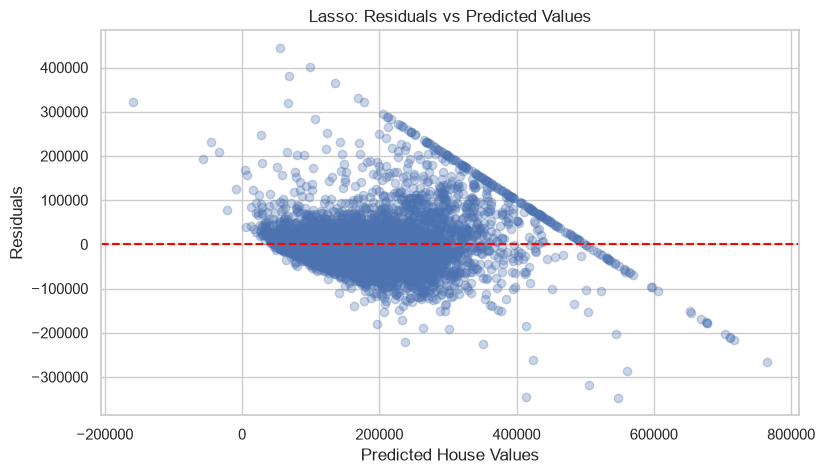

In [60]:
plt.figure(figsize=(9, 5))

plt.scatter(
    y_pred_lasso,
    lasso_residuals,
    alpha=0.3
)

plt.axhline(0, color='red', linestyle='--')

plt.xlabel('Predicted House Values')
plt.ylabel('Residuals')

plt.title('Lasso: Residuals vs Predicted Values')

plt.show()

In [61]:
# Extract trained Lasso model

lasso_model = best_lasso.named_steps['model']

# Extract feature names after preprocessing

feature_names = best_lasso.named_steps[
    'preprocessor'
].get_feature_names_out()

# Create coefficient DataFrame

lasso_coefficients = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': lasso_model.coef_
})

# Sort by absolute coefficient magnitude

lasso_coefficients['Absolute_Coefficient'] = (
    lasso_coefficients['Coefficient'].abs()
)

lasso_coefficients = lasso_coefficients.sort_values(
    by='Absolute_Coefficient',
    ascending=False
)

lasso_coefficients.head(20)

,Feature,Coefficient,Absolute_Coefficient
17,num__longitude median_income,-62770.087554,62770.087554
0,num__longitude,-52795.050664,52795.050664
1,num__latitude,-47920.163957,47920.163957
32,num__housing_median_age population,-47113.807567,47113.807567
52,num__population median_income,-46155.944852,46155.944852
47,num__total_bedrooms median_income,38510.245935,38510.245935
8,num__rooms_per_household,37058.871067,37058.871067
67,cat__ocean_proximity_INLAND,-35666.607677,35666.607677
31,num__housing_median_age total_bedrooms,28881.271012,28881.271012
33,num__housing_median_age households,27593.732587,27593.732587


In [62]:
zero_coefficients = np.sum(
    lasso_model.coef_ == 0
)

total_coefficients = len(lasso_model.coef_)

print("Total Features:", total_coefficients)

print("Zero Coefficients:", zero_coefficients)

print(
    "Percentage Eliminated:",
    round(zero_coefficients / total_coefficients * 100, 2),
    "%"
)

Total Features: 71
Zero Coefficients: 34
Percentage Eliminated: 47.89 %


In [63]:
# Create model comparison DataFrame
model_comparison = pd.DataFrame({
    'Model': ['OLS', 'Ridge', 'Lasso'],

    'MAE': [
        ols_mae,
        ridge_mae,
        lasso_mae
    ],

    'RMSE': [
        ols_rmse,
        ridge_rmse,
        lasso_rmse
    ],

    'R2 Score': [
        ols_r2,
        ridge_r2,
        lasso_r2
    ]
})

# Display results

model_comparison.round(2)

,Model,MAE,RMSE,R2 Score
0,OLS,69788.74,179952.04,-1.47
1,Ridge,48412.60,67804.90,0.65
2,Lasso,47484.97,66504.97,0.66


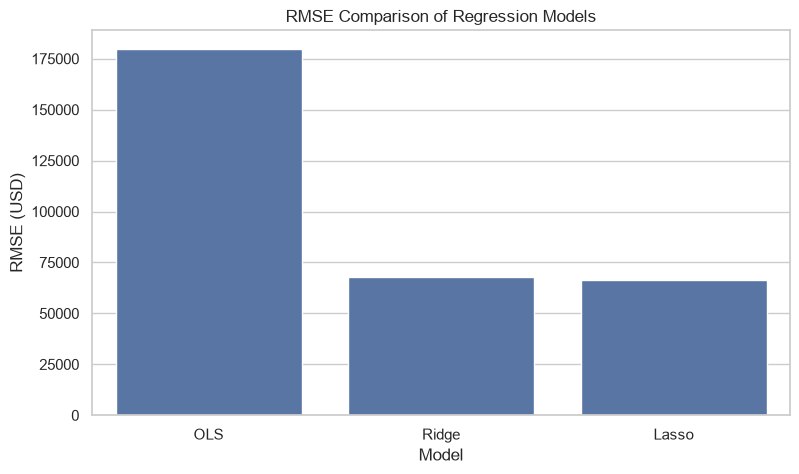

In [64]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=model_comparison,
    x='Model',
    y='RMSE'
)
plt.title('RMSE Comparison of Regression Models')
plt.ylabel('RMSE (USD)')
plt.show()

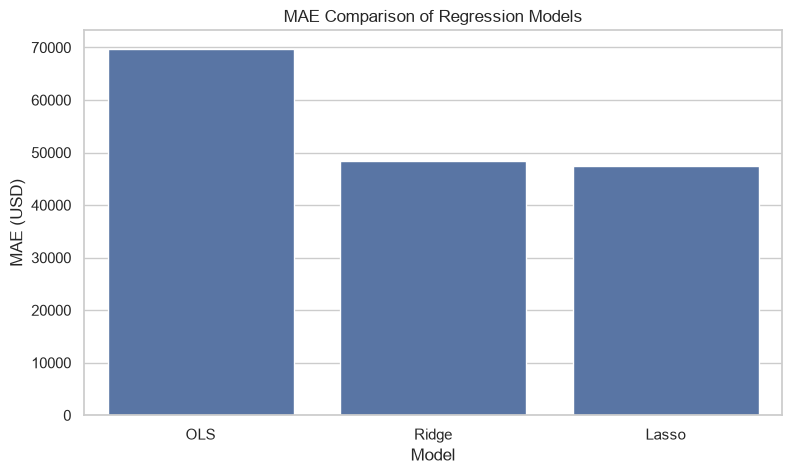

In [65]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='MAE'
)

plt.title('MAE Comparison of Regression Models')
plt.ylabel('MAE (USD)')
plt.show()

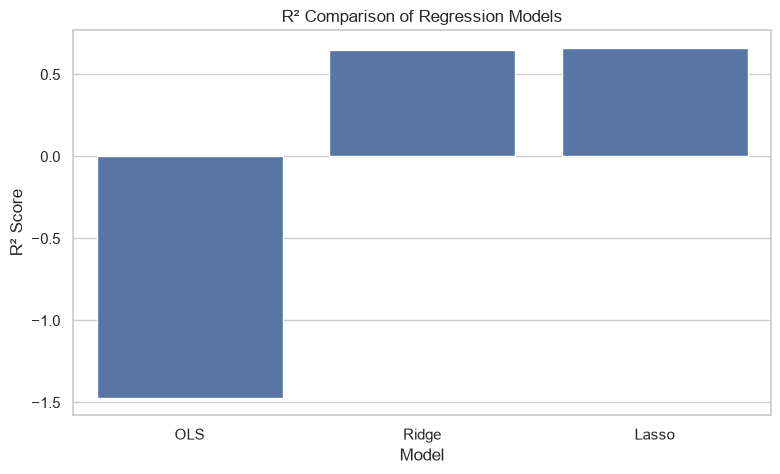

In [66]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='R2 Score'
)

plt.title('R² Comparison of Regression Models')
plt.ylabel('R² Score')
plt.show()

In [67]:
# model with lowest RMSE
best_model = model_comparison.loc[
    model_comparison['RMSE'].idxmin()
]
print("Best Performing Model:")
print(best_model)

Best Performing Model:
Model              Lasso
MAE         47484.973822
RMSE        66504.974409
R2 Score        0.662479
Name: 2, dtype: object


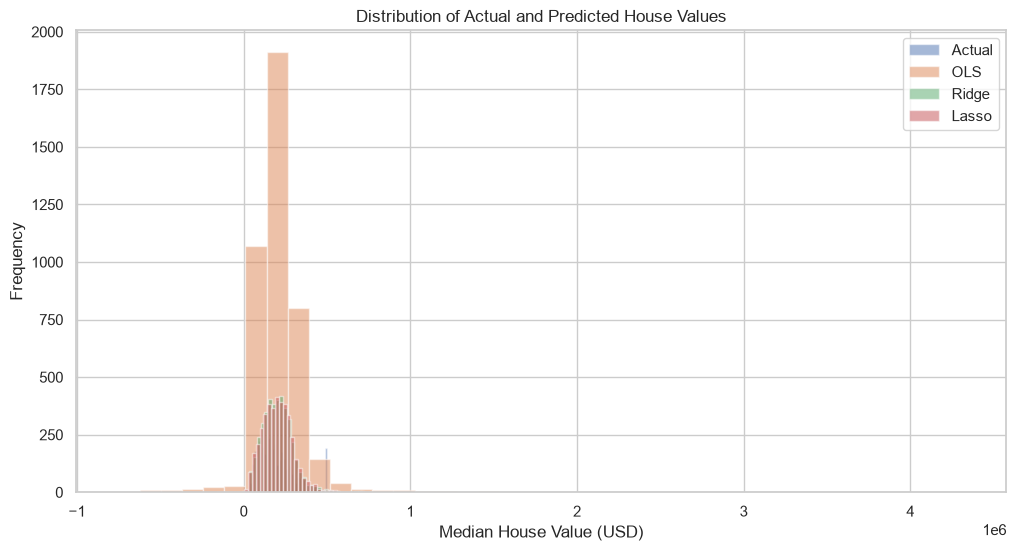

In [68]:
plt.figure(figsize=(12, 6))

plt.hist(
    y_test,
    bins=40,
    alpha=0.5,
    label='Actual'
)

plt.hist(
    y_pred_ols,
    bins=40,
    alpha=0.5,
    label='OLS'
)

plt.hist(
    y_pred_ridge,
    bins=40,
    alpha=0.5,
    label='Ridge'
)

plt.hist(
    y_pred_lasso,
    bins=40,
    alpha=0.5,
    label='Lasso'
)

plt.title('Distribution of Actual and Predicted House Values')
plt.xlabel('Median House Value (USD)')
plt.ylabel('Frequency')
plt.legend()

plt.show()

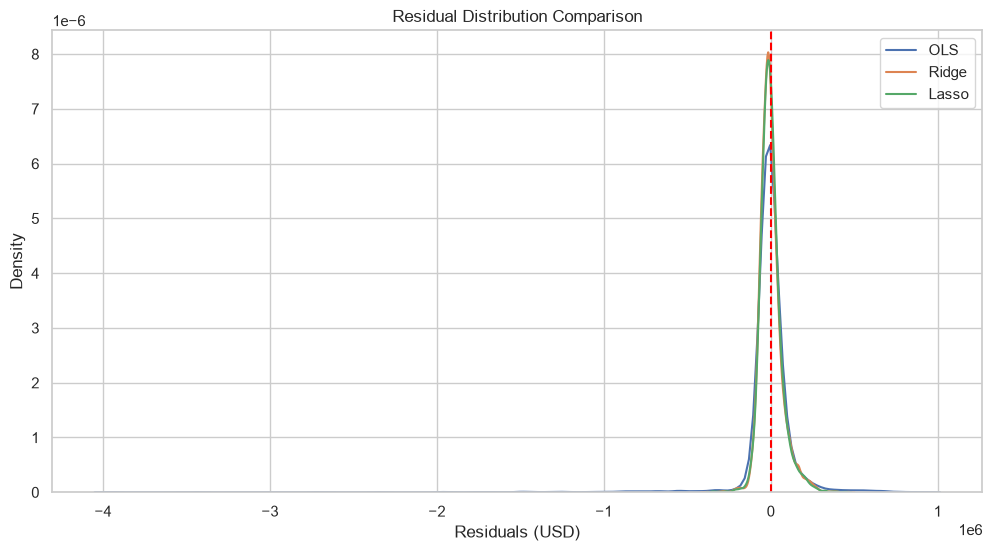

In [69]:
plt.figure(figsize=(12, 6))

sns.kdeplot(
    ols_residuals,
    label='OLS'
)

sns.kdeplot(
    ridge_residuals,
    label='Ridge'
)

sns.kdeplot(
    lasso_residuals,
    label='Lasso'
)

plt.axvline(0, color='red', linestyle='--')

plt.title('Residual Distribution Comparison')
plt.xlabel('Residuals (USD)')
plt.legend()

plt.show()